# Deceptive Miss

**Which pitchers throw the most balls that look like strikes?**

A pitch-quality metric built on 2026 MLB Statcast data. For every pitch that 
misses the zone, the **projected strike percentage** measures how much of its flight 
that it looked like it would cross the plate as a strike. A **deceptive miss**, derived
from that, is one whose projected strike percentage exceeds a data-driven threshold,
meaning the pitch looked like a strike for a large majority of the flight before 
finishing outside of the strike zone.

This notebooks displays the core analysis and findings. See the pipeline logic in `functions.py`.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import deceptive_miss as dm
import itables
itables.init_notebook_mode(all_interactive=True)
itables.options.column_filters = "header"

## Pull Pitch Data

This pulls Statcast data of all pitches thrown in the 2026 MLB season.

In [2]:
pitches = dm.load_pitches()
print(f"{len(pitches):,} pitches loaded ({dm.SEASON_START} to {dm.SEASON_END})")
display(pitches)

This is a large query, it may take a moment to complete


100%|██████████| 166/166 [00:18<00:00,  8.95it/s]


629,012 pitches loaded (2026-03-25 to 2026-09-06)


Loading ITables v2.7.0 from the init_notebook_mode cell... (need help?)


## Classify Zone Miss
This function determines which pitches missed the zone and which did not-- this is different from being classified as a ball or strike. This is independant from any umpire decisions or balls put in play/fouled off.

In [3]:
pitches = dm.classify_zone_miss(pitches)
print(f"ABS zone-miss rate across all pitches: {pitches['missed_zone'].mean():.2%}")

misses = pitches[pitches["missed_zone"]]
print(f"{len(misses):,} pitches missed the zone")

ABS zone-miss rate across all pitches: 52.52%
330,338 pitches missed the zone


## Compute Projected Strike Percentage
This function calculates the percentage of the flight path that a ball looks like it is going to cross the plate within the ABS strike zone. This is done by taking 100 points throughout the pitch's flight, and at each one, drawing a straight line to the zone to determine if it would land within (accounting for the negative velocity that causes the pitch to drop on the way).

In [4]:
misses["proj_strike_pct"] = dm.calc_proj_strike_pct(misses)
misses["proj_strike_pct"].describe(percentiles=[.5, .75, .9, .95, .99])

Loading ITables v2.7.0 from the init_notebook_mode cell... (need help?)


## Plot Distribution
This plot displays all pitches that missed the zone and shows the distribution of the percentage of their flight path during which they appeared to be a strike. While the majority of pitches are bad misses—they never look like a strike—the remaining pitches follow a bell-shaped distribution. Pitches at or above the 90th percentile for percentage of flight appearing to be a strike are classified as deceptive misses.

330,338 pitches remaining


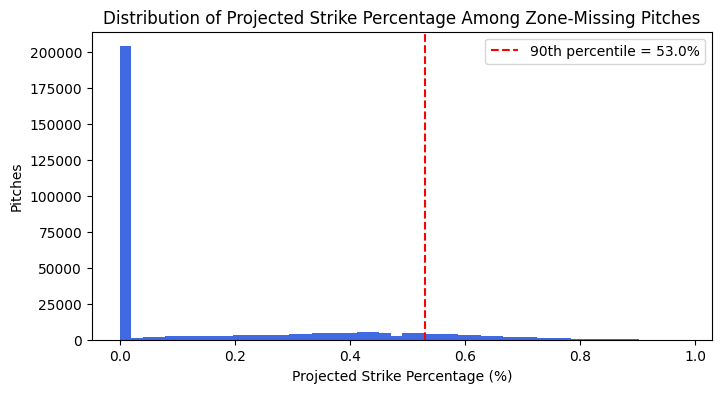

In [5]:
misses, threshold_value = dm.add_deceptive_miss_overall(misses)
print(f"{len(misses):,} pitches remaining")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(misses["proj_strike_pct"], bins=50, color="royalblue")
ax.axvline(threshold_value, color="red", linestyle="--",
           label=f"{dm.THRESHOLD_PERCENTILE}th percentile = {threshold_value:.1%}")
ax.set_xlabel("Projected Strike Percentage (%)")
ax.set_ylabel("Pitches")
ax.set_title("Distribution of Projected Strike Percentage Among Zone-Missing Pitches")
ax.legend()
plt.show()

This plot is the same as the one above, but it removes the large bucket of pitches that look like a strike for exactly 0% of their flight path. This creates a more detailed look at the pitches that were at least somewhat competitive.

203,665 pitches excluded (projected strike for exactly 0% of flight path)
126,673 pitches remaining


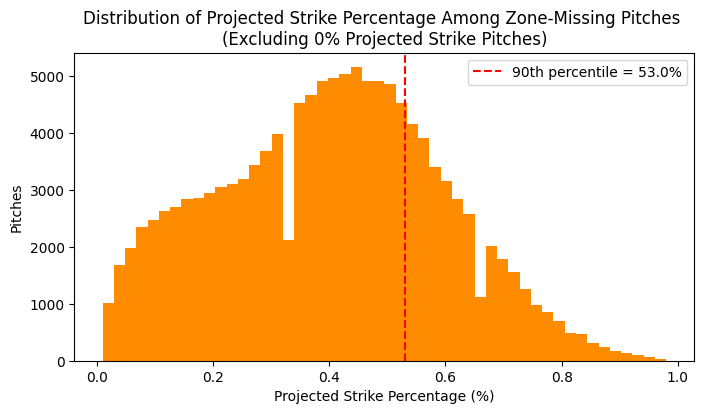

In [6]:
proj_strike_nonzero = misses[misses["proj_strike_pct"] > 0]
print(f"{len(misses) - len(proj_strike_nonzero):,} pitches excluded (projected strike for exactly 0% of flight path)")
print(f"{len(proj_strike_nonzero):,} pitches remaining")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(proj_strike_nonzero["proj_strike_pct"], bins=50, color="darkorange")
ax.axvline(threshold_value, color="red", linestyle="--",
           label=f"{dm.THRESHOLD_PERCENTILE}th percentile = {threshold_value:.1%}")
ax.set_xlabel("Projected Strike Percentage (%)")
ax.set_ylabel("Pitches")
ax.set_title("Distribution of Projected Strike Percentage Among Zone-Missing Pitches \n(Excluding 0% Projected Strike Pitches)")
ax.legend()
plt.show()

## Build Overall Leaderboard
This leaderboard shows the pitchers that have the most deceptive misses in the 2026 MLB season, accompanied by the average length that their pitches were projected to be strike and how many of their zone misses are classified as a deceptive miss.

In [7]:
leaderboard_overall = dm.build_leaderboard_overall(misses)
display(leaderboard_overall)

Loading ITables v2.7.0 from the init_notebook_mode cell... (need help?)


## Build Pitch Type Leaderboard
Each pitch type gets its own threshold, computed within that type only, since their shapes are not the same and consequently, their distribution of how much pitches look like a strike are not the same. Types with too few zone-missing pitches leaguewide are excluded.

This leaderboard shows the pitchers that have the most deceptive misses by pitch type in the 2026 MLB season, accompanied by the same statistics as before but specific to pitch type.

In [8]:
misses_by_type, thresholds_by_type = dm.add_deceptive_miss_by_pitch_type(misses)
print(f"Projected strike percentage thresholds by pitch type: \n{thresholds_by_type.sort_values(ascending=False)}")

Projected strike percentage thresholds by pitch type: 
pitch_type
FS    0.600
CH    0.590
SL    0.590
SI    0.550
ST    0.530
SV    0.520
FO    0.516
FC    0.510
KC    0.510
CU    0.480
KN    0.435
FA    0.340
FF    0.260
EP    0.160
Name: threshold_by_type, dtype: float64


In [9]:
leaderboard_by_type = dm.build_leaderboard_by_pitch_type(misses_by_type)

leaderboard_by_type.sort_values(["pitch_type", "deceptive_misses"], ascending=[True, False])

Loading ITables v2.7.0 from the init_notebook_mode cell... (need help?)


## Validation

Now that the statistic has been created, it is time to prove that it is meaningful. A first check would be to compare chase rate as the projected strike percentage improves. Naturally, we would expect those to increase as the pitch becomes more deceptive.

Looking at the results below, that does appear to be the case, to an extent. For the majority of bins, as the projected strike percentage increases, so does the chase rate. This is until the last two bins, where we see a decrease. This can be explained, though, by the called strike rates. Since those pitches look like a strike for so long, they are landing extremely close to the strike zone. So much so, that many are a called strike rather than a swinging strike, reducing the chase rate.

In [10]:
misses = dm.add_swing_outcomes(misses)
psp_validation = dm.validate_proj_strike_pct(misses)
psp_validation

Loading ITables v2.7.0 from the init_notebook_mode cell... (need help?)


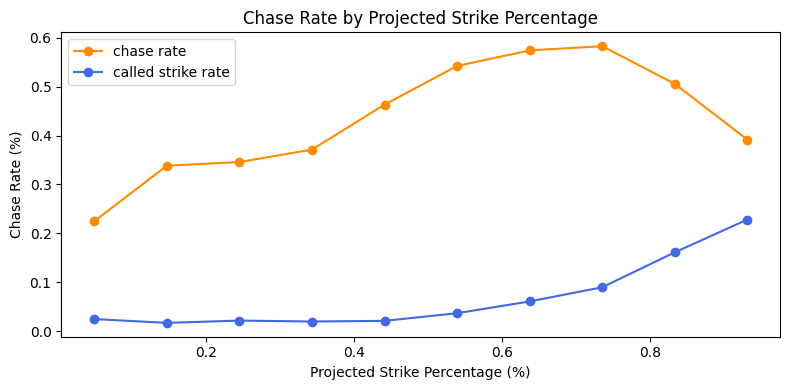

In [11]:
bin_midpoints = psp_validation.index.astype("interval").mid
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(bin_midpoints, psp_validation["chase_rate"], marker="o", label="chase rate", color="darkorange")
ax.plot(bin_midpoints, psp_validation["called_strike_rate"], marker="o", label="called strike rate", color="royalblue")
ax.set_xlabel("Projected Strike Percentage (%)")
ax.set_ylabel("Chase Rate (%)")
ax.set_title("Chase Rate by Projected Strike Percentage")
ax.legend()
plt.tight_layout()
plt.show()

As seen above, the final location of the pitch has a big effect on chase rate. Additionally, a simple objection to the validation step above would be that people swing more often at pitches that finish close to the zone, so how long it looks like a strike does not necessarily predict that. 

The way to strengthen our validation is to compare amongst pitches that finished equally close to the zone edge. Do the ones with a higher projected strike percentage get chased more?

The chart and plot below confirms that is true! Controlling for distance by binning pitches by how close they finish to the strike zone, the median projected strike percentage is calculated. Then, for pitches above the median (more deceptive misses) and below the median (less deceptive misses), the chase rates are calculated. For each bin, the pitches with the higher projected strike percentage have a higher chase rate than the ones with a lower one, confirming that there is real merit to this statistic!

In [12]:
psp_validation_dist = dm.validate_proj_strike_pct_dist(misses)
psp_validation_dist

Loading ITables v2.7.0 from the init_notebook_mode cell... (need help?)


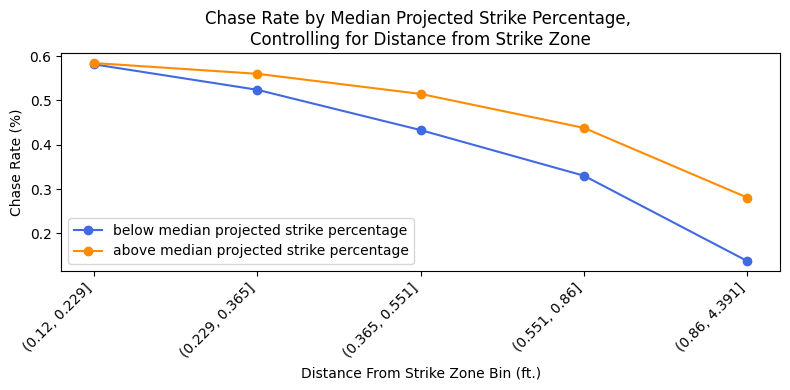

In [13]:
x = np.arange(len(psp_validation_dist))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, psp_validation_dist["below_proj_strike_pct_med"], marker="o",
        label="below median projected strike percentage", color="royalblue")
ax.plot(x, psp_validation_dist["above_proj_strike_pct_med"], marker="o",
        label="above median projected strike percentage", color="darkorange")
ax.set_xticks(x)
ax.set_xticklabels([str(bin) for bin in psp_validation_dist.index], rotation=45, ha="right")
ax.set_ylabel("Chase Rate (%)")
ax.set_xlabel("Distance From Strike Zone Bin (ft.)")
ax.set_title("Chase Rate by Median Projected Strike Percentage, \nControlling for Distance from Strike Zone")
ax.legend()
plt.tight_layout()
plt.show()

In the same fashion, it is time to validate the deceptive miss as a statistic. If this threshold is meaningful, deceptive misses should also have a higher chase rate than non-deceptive ones. In the chart and plot below, we can confirm this is the case, and it is drastic!

In [14]:
dm_validation = dm.validate_deceptive_miss(misses)
dm_validation

Loading ITables v2.7.0 from the init_notebook_mode cell... (need help?)


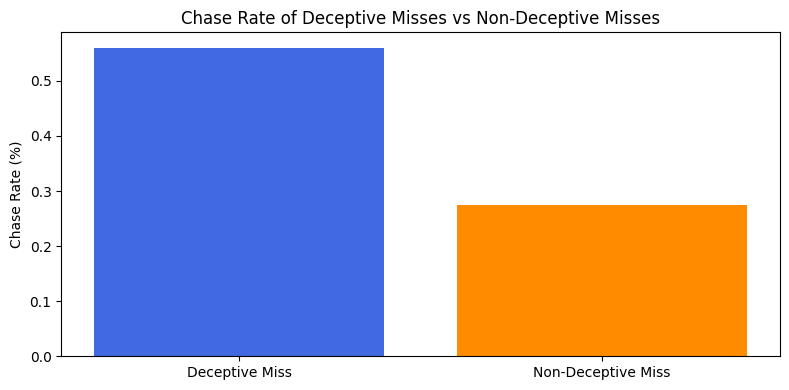

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    ["Deceptive Miss", "Non-Deceptive Miss"],
    [dm_validation.loc[True, "chase_rate"], dm_validation.loc[False, "chase_rate"]],
    color=["royalblue", "darkorange"],
)
ax.set_ylabel("Chase Rate (%)")
ax.set_title("Chase Rate of Deceptive Misses vs Non-Deceptive Misses")
plt.tight_layout()
plt.show()

Like previously, it is also crucial that the distance pitches miss from the strike zone is controlled. It is still apparent that deceptive misses are chased much more often than non-deceptive ones! 

In [16]:
dm_validation_dist, max_deceptive_dist = dm.validate_deceptive_miss_dist(misses)
print(f"restricting to dist_from_zone <= {max_deceptive_dist:.3f} ft "
      f"({len(misses[misses['dist_from_zone'] <= max_deceptive_dist]):,} of {len(misses):,} pitches, "
      f"{(misses['dist_from_zone'] <= max_deceptive_dist).mean():.1%})")
print("\nchase_rate:"); 
dm_validation_dist

restricting to dist_from_zone <= 0.527 ft (157,850 of 330,338 pitches, 47.8%)

chase_rate:


Loading ITables v2.7.0 from the init_notebook_mode cell... (need help?)


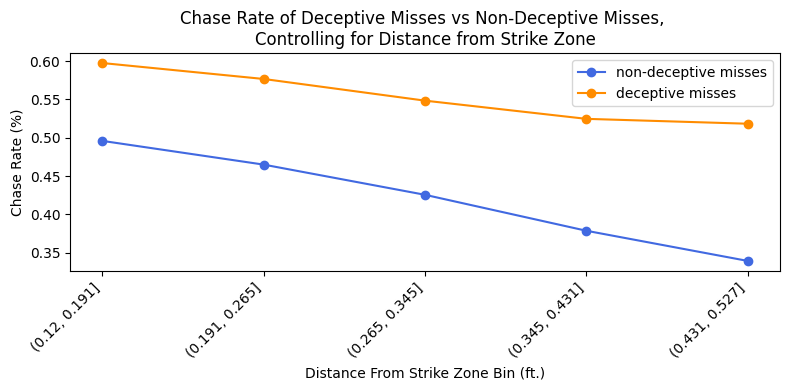

In [17]:
x = np.arange(len(dm_validation_dist))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, dm_validation_dist[False], marker="o", label="non-deceptive misses", color="royalblue")
ax.plot(x, dm_validation_dist[True], marker="o", label="deceptive misses", color="darkorange")
ax.set_xticks(x)
ax.set_xticklabels([str(bin) for bin in dm_validation_dist.index], rotation=45, ha="right")
ax.set_ylabel("Chase Rate (%)")
ax.set_xlabel("Distance From Strike Zone Bin (ft.)")
ax.set_title("Chase Rate of Deceptive Misses vs Non-Deceptive Misses, \nControlling for Distance from Strike Zone")
ax.legend()
plt.tight_layout()
plt.show()

## Conclusions

This analysis exhibits how the deceptive miss statistic is created, which pitchers have the most in the MLB in 2026 (overall and by pitch type), and validates that this statistic matters by proving there is a direct relationship between the metric and chase rate. Controlling for distance from the plate, more deceptive misses have a higher chase rate than less deceptive misses. The difference between those two groups grows larger the further the pitch lands from the plate, which makes sense. A non-competitive miss far from the strike zone is not likely to generate a chase, but a devastating breaking ball that looks like a strike but then falls off towards the end of its flight and finishes over 0.5 feet from the zone seems more plausible to generate a chase. This can be used to see which pitchers have been effective with their misses!